In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/TEST_INFERENCE_COMPLETED.txt
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/artifact_summary.json
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/confidence_intervals.json
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/final_segmentation_evaluation.json
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/patient_bootstrap_segmentation.csv
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/test_metrics_by_abnormality_type.csv
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/test_metrics_by_lesion_size.csv
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/test_segmentation_analysis.csv
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/test_segmentation_metrics.csv
/kaggle/input/datasets/ishaans23/final-segmentation-evaluation-artifact/thr

In [2]:
from pathlib import Path
import json
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import (
    resnet50,
    ResNet50_Weights,
)

from tqdm.auto import tqdm

from IPython.display import (
    display as notebook_display,
)

In [3]:
SEED = 42

TARGET_HEIGHT = 1024
TARGET_WIDTH = 640

OUTPUT_DIR = Path(
    "/kaggle/working/classifier_gradcam"
)

FIGURE_DIR = (
    OUTPUT_DIR / "figures"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda:0
GPU: Tesla T4


In [4]:
KAGGLE_INPUT_ROOT = Path(
    "/kaggle/input"
)

dataset_candidates = []

for cache_info_path in KAGGLE_INPUT_ROOT.rglob(
    "cache_info.json"
):

    candidate_root = (
        cache_info_path.parent
    )

    required = [
        candidate_root / "npy",
        candidate_root / "masks",
        candidate_root / "splits",
    ]

    if all(
        path.exists()
        for path in required
    ):
        dataset_candidates.append(
            candidate_root
        )

assert len(dataset_candidates) > 0

dataset_candidates = sorted(
    dataset_candidates,
    key=lambda path: len(str(path)),
)

PROJECT_ROOT = (
    dataset_candidates[0]
)

print("Dataset:")
print(PROJECT_ROOT)

Dataset:
/kaggle/input/datasets/ishaans23/cbis-ddsm-training


In [5]:
classifier_candidates = list(
    KAGGLE_INPUT_ROOT.rglob(
        "resnet50_layer4_best.pth"
    )
)

assert len(classifier_candidates) > 0, (
    "Final classifier checkpoint not found."
)

CLASSIFIER_CHECKPOINT_PATH = (
    classifier_candidates[0]
)

print(
    "Classifier checkpoint:"
)

print(
    CLASSIFIER_CHECKPOINT_PATH
)

Classifier checkpoint:
/kaggle/input/datasets/ishaans23/final-classifier-artifact/resnet50_layer4_best.pth


In [8]:
# ============================================================
# LOCATE CLASSIFIER EVALUATION ARTIFACT
# ============================================================

import zipfile


def find_test_predictions(
    search_root,
):

    candidates = list(
        search_root.rglob(
            "test_predictions.csv"
        )
    )

    return candidates


# ------------------------------------------------------------
# First try normal Kaggle input directories
# ------------------------------------------------------------

prediction_candidates = (
    find_test_predictions(
        KAGGLE_INPUT_ROOT
    )
)


# ------------------------------------------------------------
# If not found, search ZIP files and extract
# ------------------------------------------------------------

if len(prediction_candidates) == 0:

    zip_candidates = list(
        KAGGLE_INPUT_ROOT.rglob(
            "*.zip"
        )
    )

    matching_zip = None

    for zip_path in zip_candidates:

        try:

            with zipfile.ZipFile(
                zip_path,
                "r",
            ) as archive:

                filenames = (
                    archive.namelist()
                )

                if any(
                    Path(name).name
                    == "test_predictions.csv"

                    for name in filenames
                ):

                    matching_zip = (
                        zip_path
                    )

                    break

        except zipfile.BadZipFile:
            continue


    assert matching_zip is not None, (
        "Could not find a classifier "
        "evaluation ZIP containing "
        "test_predictions.csv."
    )


    print(
        "Found classifier "
        "evaluation ZIP:"
    )

    print(
        matching_zip
    )


    EXTRACT_DIR = Path(
        "/kaggle/working/"
        "classifier_evaluation_extracted"
    )


    if EXTRACT_DIR.exists():

        shutil.rmtree(
            EXTRACT_DIR
        )


    EXTRACT_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )


    with zipfile.ZipFile(
        matching_zip,
        "r",
    ) as archive:

        archive.extractall(
            EXTRACT_DIR
        )


    prediction_candidates = (
        find_test_predictions(
            EXTRACT_DIR
        )
    )


# ------------------------------------------------------------
# VERIFY
# ------------------------------------------------------------

assert len(prediction_candidates) > 0, (
    "Classifier test_predictions.csv "
    "still could not be found."
)


TEST_PREDICTIONS_PATH = (
    prediction_candidates[0]
)


print(
    "\nClassifier predictions:"
)

print(
    TEST_PREDICTIONS_PATH
)


Classifier predictions:
/kaggle/input/datasets/ishaans23/classifier-evaluation/test_predictions.csv


In [9]:
test_df = pd.read_csv(
    PROJECT_ROOT
    / "splits"
    / "test.csv"
)

pred_df = pd.read_csv(
    TEST_PREDICTIONS_PATH
)


print(
    "Test metadata:",
    len(test_df)
)

print(
    "Classifier predictions:",
    len(pred_df)
)


notebook_display(
    pred_df.head()
)

Test metadata: 394
Classifier predictions: 394


,image_key,target,probability,patient_id,pathology,abnormality_type,predicted_label
0,P_00014_LEFT_CC,1,0.164307,P_00014,MALIGNANT,calcification,0
1,P_00014_LEFT_MLO,1,0.155029,P_00014,MALIGNANT,calcification,0
2,P_00019_RIGHT_CC,0,0.164307,P_00019,BENIGN,calcification,0
3,P_00019_RIGHT_MLO,0,0.644043,P_00019,BENIGN,calcification,1
4,P_00023_RIGHT_CC,1,0.715820,P_00023,MALIGNANT,mass,1


In [10]:
print(
    pred_df.columns.tolist()
)

print(
    "\nTest columns:"
)

print(
    test_df.columns.tolist()
)

['image_key', 'target', 'probability', 'patient_id', 'pathology', 'abnormality_type', 'predicted_label']

Test columns:
['image_key', 'patient_id', 'side', 'view', 'abnormality_type', 'pathology', 'malignant', 'mass_present', 'calc_present', 'mixed_pathology', 'lesion_count', 'source_datasets', 'source_pathologies', 'height', 'width', 'mask_pixels', 'dropped_mask_pixels', 'crop_rmin', 'crop_rmax', 'crop_cmin', 'crop_cmax', 'npy_path', 'mask_path', 'source_partitions', 'mask_alignment_methods', 'source_image_dicoms', 'source_mask_dicoms', 'split']


In [11]:
# ============================================================
# CLASSIFICATION OUTCOME LABELS
# ============================================================

analysis_df = pred_df.copy()


def classification_outcome(row):

    target = int(
        row["target"]
    )

    prediction = int(
        row["predicted_label"]
    )

    if target == 1 and prediction == 1:
        return "TP"

    if target == 0 and prediction == 0:
        return "TN"

    if target == 0 and prediction == 1:
        return "FP"

    if target == 1 and prediction == 0:
        return "FN"

    raise ValueError(
        "Unexpected target/prediction."
    )


analysis_df[
    "outcome"
] = analysis_df.apply(
    classification_outcome,
    axis=1,
)


print(
    analysis_df[
        "outcome"
    ].value_counts()
)


notebook_display(
    analysis_df[
        [
            "image_key",
            "target",
            "probability",
            "predicted_label",
            "outcome",
            "abnormality_type",
        ]
    ].head()
)

outcome
TN    155
TP    104
FN     78
FP     57
Name: count, dtype: int64


,image_key,target,probability,predicted_label,outcome,abnormality_type
0,P_00014_LEFT_CC,1,0.164307,0,FN,calcification
1,P_00014_LEFT_MLO,1,0.155029,0,FN,calcification
2,P_00019_RIGHT_CC,0,0.164307,0,TN,calcification
3,P_00019_RIGHT_MLO,0,0.644043,1,FP,calcification
4,P_00023_RIGHT_CC,1,0.715820,1,TP,mass


In [12]:
# ============================================================
# LOAD CLASSIFIER METADATA
# ============================================================

metadata_candidates = list(
    KAGGLE_INPUT_ROOT.rglob(
        "model_metadata.json"
    )
)

assert len(metadata_candidates) > 0

CLASSIFIER_METADATA_PATH = (
    metadata_candidates[0]
)


with open(
    CLASSIFIER_METADATA_PATH,
    "r",
) as f:

    classifier_metadata = json.load(f)


print(
    "Metadata:"
)

print(
    CLASSIFIER_METADATA_PATH
)

print(
    json.dumps(
        classifier_metadata,
        indent=2,
    )
)

Metadata:
/kaggle/input/datasets/ishaans23/final-classifier-artifact/model_metadata.json
{
  "project": "CBIS-DDSM Breast Cancer Classification",
  "architecture": "ResNet-50",
  "pretrained_weights": "ResNet50_Weights.DEFAULT",
  "selected_stage": "layer4",
  "checkpoint": "resnet50_layer4_best.pth",
  "task": "binary malignancy classification",
  "class_mapping": {
    "0": "non-malignant",
    "1": "malignant"
  },
  "input": {
    "height": 1024,
    "width": 640,
    "channels": 3,
    "source_dtype": "uint16",
    "scaling": "divide by 65535",
    "grayscale_to_rgb": true
  },
  "normalization": {
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  },
  "training": {
    "batch_size": 4,
    "seed": 42,
    "head_learning_rate": 0.001,
    "layer4_learning_rate": 1e-05,
    "fc_finetune_learning_rate": 0.0001,
    "weight_decay": 0.0001
  },
  "validation": {
    "best_head_roc_auc": 0.7316090838509317,
    "best_l

In [13]:
# ============================================================
# CLASSIFIER NORMALIZATION
# ============================================================

resnet_weights = (
    ResNet50_Weights.DEFAULT
)

weight_transforms = (
    resnet_weights.transforms()
)


NORMALIZATION_MEAN = (
    weight_transforms.mean
)

NORMALIZATION_STD = (
    weight_transforms.std
)


mean_tensor = torch.tensor(
    NORMALIZATION_MEAN,
    dtype=torch.float32,
    device=device,
).view(
    1,
    3,
    1,
    1,
)


std_tensor = torch.tensor(
    NORMALIZATION_STD,
    dtype=torch.float32,
    device=device,
).view(
    1,
    3,
    1,
    1,
)


print(
    "Mean:",
    NORMALIZATION_MEAN
)

print(
    "Std:",
    NORMALIZATION_STD
)

Mean: [0.485, 0.456, 0.406]
Std: [0.229, 0.224, 0.225]


In [14]:
# ============================================================
# REBUILD RESNET-50 CLASSIFIER
# ============================================================

model = resnet50(
    weights=None
)


model.fc = nn.Linear(
    model.fc.in_features,
    1,
)


checkpoint = torch.load(
    CLASSIFIER_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)


model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)


model = model.to(
    device
)

model.eval()


print(
    "Classifier checkpoint epoch:",
    checkpoint["epoch"]
)


print(
    "Validation ROC-AUC:",
    checkpoint[
        "val_metrics"
    ]["roc_auc"]
)

Classifier checkpoint epoch: 3
Validation ROC-AUC: 0.8227387422360248


In [16]:
# ============================================================
# CLASSIFIER INPUT HELPER
# ============================================================

def load_classifier_image(
    image_key,
):

    row = test_df.loc[
        test_df[
            "image_key"
        ]
        == image_key
    ].iloc[0]


    image = np.load(
        PROJECT_ROOT
        / row[
            "npy_path"
        ]
    )


    assert image.shape == (
        TARGET_HEIGHT,
        TARGET_WIDTH,
    )


    image_float = (
        image.astype(
            np.float32
        )
        / 65535.0
    )


    tensor = torch.from_numpy(
        image_float
    ).to(
        device
    )


    tensor = (
        tensor
        .unsqueeze(0)
        .unsqueeze(0)
        .repeat(
            1,
            3,
            1,
            1,
        )
    )


    tensor = (
        tensor
        - mean_tensor
    ) / std_tensor


    return (
        image,
        tensor,
        row,
    )

In [17]:
# ============================================================
# VERIFY SAVED CLASSIFIER PREDICTION
# ============================================================

example_row = (
    analysis_df.iloc[0]
)

example_key = (
    example_row[
        "image_key"
    ]
)


image, image_tensor, _ = (
    load_classifier_image(
        example_key
    )
)


with torch.inference_mode():

    logit = model(
        image_tensor
    ).squeeze()

    probability = torch.sigmoid(
        logit
    ).item()


saved_probability = float(
    example_row[
        "probability"
    ]
)


print(
    "Image:",
    example_key
)

print(
    "Fresh probability:",
    probability
)

print(
    "Saved probability:",
    saved_probability
)

print(
    "Absolute difference:",
    abs(
        probability
        - saved_probability
    )
)

Image: P_00014_LEFT_CC
Fresh probability: 0.16645093262195587
Saved probability: 0.16430664
Absolute difference: 0.002144292621955868


In [22]:
# ============================================================
# GRAD-CAM
# ============================================================

class GradCAM:

    def __init__(
        self,
        model,
        target_layer,
    ):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )


    def _save_gradient(
        self,
        gradient,
    ):
        self.gradients = gradient


    def _forward_hook(
        self,
        module,
        inputs,
        output,
    ):
        self.activations = output

        output.register_hook(
            self._save_gradient
        )


    def generate(
        self,
        input_tensor,
        predicted_label,
    ):

        self.model.zero_grad(
            set_to_none=True
        )

        logit = self.model(
            input_tensor
        ).squeeze()


        if int(predicted_label) == 1:
            target_score = logit

        else:
            target_score = -logit


        target_score.backward()


        gradients = self.gradients
        activations = self.activations


        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True,
        )


        cam = (
            weights
            * activations
        ).sum(
            dim=1,
            keepdim=True,
        )


        cam = F.relu(
            cam
        )


        cam = F.interpolate(
            cam,
            size=(
                TARGET_HEIGHT,
                TARGET_WIDTH,
            ),
            mode="bilinear",
            align_corners=False,
        )


        cam = cam[
            0,
            0,
        ]


        cam_min = cam.min()
        cam_max = cam.max()


        cam = (
            cam
            - cam_min
        ) / (
            cam_max
            - cam_min
            + 1e-8
        )


        return (
            cam.detach()
            .cpu()
            .numpy()
        )


    def remove_hooks(
        self,
    ):
        self.forward_handle.remove()

In [27]:
gradcam.remove_hooks()

gradcam = GradCAM(
    model=model,
    target_layer=model.layer4[-1],
)

print(
    "Grad-CAM target layer:"
)

print(
    model.layer4[-1]
)

Grad-CAM target layer:
Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)


In [28]:
# ============================================================
# SINGLE TRUE-POSITIVE GRAD-CAM CHECK
# ============================================================

tp_row = (
    analysis_df[
        analysis_df[
            "outcome"
        ]
        == "TP"
    ]
    .sort_values(
        "probability",
        ascending=False,
    )
    .iloc[0]
)


image_key = (
    tp_row[
        "image_key"
    ]
)


image, image_tensor, metadata = (
    load_classifier_image(
        image_key
    )
)


cam = gradcam.generate(
    input_tensor=image_tensor,
    predicted_label=tp_row[
        "predicted_label"
    ],
)


mask = cv2.imread(
    str(
        PROJECT_ROOT
        / metadata[
            "mask_path"
        ]
    ),
    cv2.IMREAD_GRAYSCALE,
)


mask = (
    mask > 0
)


print(
    "Image:",
    image_key
)

print(
    "Outcome:",
    tp_row[
        "outcome"
    ]
)

print(
    "Probability:",
    tp_row[
        "probability"
    ]
)

print(
    "Abnormality:",
    tp_row[
        "abnormality_type"
    ]
)

Image: P_01343_LEFT_CC
Outcome: TP
Probability: 0.9995117
Abnormality: mass


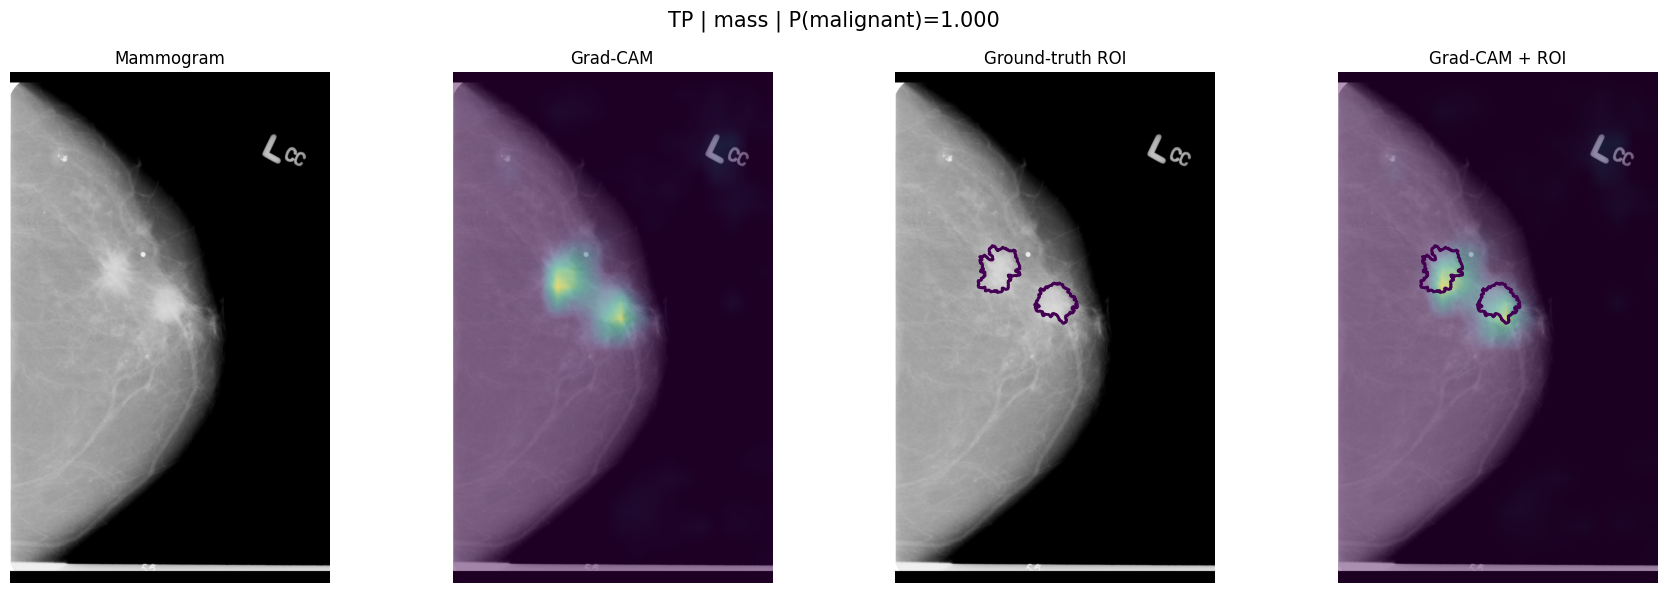

In [29]:
# ============================================================
# GRAD-CAM SANITY FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(
        18,
        6,
    ),
)


axes[0].imshow(
    image,
    cmap="gray",
)

axes[0].set_title(
    "Mammogram"
)


axes[1].imshow(
    image,
    cmap="gray",
)

axes[1].imshow(
    cam,
    alpha=0.45,
)

axes[1].set_title(
    "Grad-CAM"
)


axes[2].imshow(
    image,
    cmap="gray",
)

axes[2].contour(
    mask,
    levels=[
        0.5
    ],
    linewidths=2,
)

axes[2].set_title(
    "Ground-truth ROI"
)


axes[3].imshow(
    image,
    cmap="gray",
)

axes[3].imshow(
    cam,
    alpha=0.40,
)

axes[3].contour(
    mask,
    levels=[
        0.5
    ],
    linewidths=2,
)

axes[3].set_title(
    "Grad-CAM + ROI"
)


for ax in axes:
    ax.axis(
        "off"
    )


fig.suptitle(
    (
        f"TP | "
        f"{tp_row['abnormality_type']} | "
        f"P(malignant)="
        f"{tp_row['probability']:.3f}"
    ),
    fontsize=15,
)


plt.tight_layout()

plt.show()

In [31]:
def gradcam_roi_metrics(
    cam,
    mask,
    cam_threshold=0.5,
):

    cam_binary = (
        cam >= cam_threshold
    )

    mask_binary = (
        mask > 0
    )

    intersection = np.logical_and(
        cam_binary,
        mask_binary,
    ).sum()

    cam_pixels = (
        cam_binary.sum()
    )

    mask_pixels = (
        mask_binary.sum()
    )

    union = np.logical_or(
        cam_binary,
        mask_binary,
    ).sum()


    cam_iou = (
        intersection
        / union
        if union > 0
        else 0.0
    )


    roi_coverage = (
        intersection
        / mask_pixels
        if mask_pixels > 0
        else 0.0
    )


    cam_precision = (
        intersection
        / cam_pixels
        if cam_pixels > 0
        else 0.0
    )


    mean_cam_inside_roi = (
        float(
            cam[
                mask_binary
            ].mean()
        )
        if mask_pixels > 0
        else 0.0
    )


    return {
        "cam_iou":
            float(cam_iou),

        "roi_coverage":
            float(roi_coverage),

        "cam_precision":
            float(cam_precision),

        "mean_cam_inside_roi":
            float(mean_cam_inside_roi),
    }

In [32]:
gradcam_records = []


for row in tqdm(
    analysis_df.itertuples(
        index=False
    ),
    total=len(
        analysis_df
    ),
    desc="Grad-CAM analysis",
):

    (
        image,
        image_tensor,
        metadata,
    ) = load_classifier_image(
        row.image_key
    )


    cam = gradcam.generate(
        input_tensor=image_tensor,
        predicted_label=row.predicted_label,
    )


    mask = cv2.imread(
        str(
            PROJECT_ROOT
            / metadata[
                "mask_path"
            ]
        ),
        cv2.IMREAD_GRAYSCALE,
    )


    assert mask is not None


    metrics = gradcam_roi_metrics(
        cam=cam,
        mask=mask,
        cam_threshold=0.5,
    )


    gradcam_records.append(
        {
            "image_key":
                row.image_key,

            "target":
                int(
                    row.target
                ),

            "predicted_label":
                int(
                    row.predicted_label
                ),

            "probability":
                float(
                    row.probability
                ),

            "outcome":
                row.outcome,

            "abnormality_type":
                row.abnormality_type,

            **metrics,
        }
    )


gradcam_df = pd.DataFrame(
    gradcam_records
)


gradcam_df.to_csv(
    OUTPUT_DIR
    / "gradcam_roi_metrics.csv",
    index=False,
)


notebook_display(
    gradcam_df.head()
)

Grad-CAM analysis:   0%|          | 0/394 [00:00<?, ?it/s]

,image_key,target,predicted_label,probability,outcome,abnormality_type,cam_iou,roi_coverage,cam_precision,mean_cam_inside_roi
0,P_00014_LEFT_CC,1,0,0.164307,FN,calcification,0.00000,0.0,0.00000,0.010524
1,P_00014_LEFT_MLO,1,0,0.155029,FN,calcification,0.00000,0.0,0.00000,0.009033
2,P_00019_RIGHT_CC,0,0,0.164307,TN,calcification,0.00000,0.0,0.00000,0.047548
3,P_00019_RIGHT_MLO,0,1,0.644043,FP,calcification,0.00000,0.0,0.00000,0.000000
4,P_00023_RIGHT_CC,1,1,0.715820,TP,mass,0.17247,1.0,0.17247,0.796706


In [33]:
outcome_summary = (
    gradcam_df.groupby(
        "outcome"
    )
    .agg(
        n=(
            "image_key",
            "size",
        ),

        mean_cam_iou=(
            "cam_iou",
            "mean",
        ),

        median_cam_iou=(
            "cam_iou",
            "median",
        ),

        mean_roi_coverage=(
            "roi_coverage",
            "mean",
        ),

        mean_cam_precision=(
            "cam_precision",
            "mean",
        ),

        mean_cam_inside_roi=(
            "mean_cam_inside_roi",
            "mean",
        ),
    )
    .reset_index()
)


notebook_display(
    outcome_summary
)


outcome_summary.to_csv(
    OUTPUT_DIR
    / "gradcam_metrics_by_outcome.csv",
    index=False,
)

,outcome,n,mean_cam_iou,median_cam_iou,mean_roi_coverage,mean_cam_precision,mean_cam_inside_roi
0,FN,78,0.003073,0.000000,0.005950,0.006911,0.083281
1,FP,57,0.034691,0.000000,0.052704,0.074348,0.071315
2,TN,155,0.001262,0.000000,0.009540,0.002414,0.103898
3,TP,104,0.130352,0.026446,0.197204,0.318232,0.219439


In [34]:
abnormality_summary = (
    gradcam_df.groupby(
        "abnormality_type"
    )
    .agg(
        n=(
            "image_key",
            "size",
        ),

        mean_cam_iou=(
            "cam_iou",
            "mean",
        ),

        mean_roi_coverage=(
            "roi_coverage",
            "mean",
        ),

        mean_cam_inside_roi=(
            "mean_cam_inside_roi",
            "mean",
        ),
    )
    .reset_index()
)


notebook_display(
    abnormality_summary
)


abnormality_summary.to_csv(
    OUTPUT_DIR
    / "gradcam_metrics_by_abnormality.csv",
    index=False,
)

,abnormality_type,n,mean_cam_iou,mean_roi_coverage,mean_cam_inside_roi
0,calcification,216,0.024056,0.035952,0.096333
1,mass,170,0.063087,0.103596,0.164661
2,mass+calcification,8,0.006060,0.009912,0.085798


In [35]:
selected_cases = []


for outcome in [
    "TP",
    "TN",
    "FP",
    "FN",
]:

    subset = (
        gradcam_df[
            gradcam_df[
                "outcome"
            ]
            == outcome
        ]
        .copy()
    )


    if outcome == "TP":

        subset = (
            subset.sort_values(
                "roi_coverage",
                ascending=False,
            )
        )

    elif outcome == "FN":

        subset = (
            subset.sort_values(
                "roi_coverage",
                ascending=True,
            )
        )

    else:

        subset = (
            subset.sort_values(
                "probability",
                ascending=(
                    outcome
                    == "TN"
                ),
            )
        )


    selected_cases.append(
        subset.head(2)
    )


selected_cases_df = pd.concat(
    selected_cases,
    ignore_index=True,
)


notebook_display(
    selected_cases_df[
        [
            "image_key",
            "outcome",
            "probability",
            "abnormality_type",
            "roi_coverage",
            "cam_iou",
        ]
    ]
)

,image_key,outcome,probability,abnormality_type,roi_coverage,cam_iou
0,P_00023_RIGHT_CC,TP,0.715820,mass,1.000000,0.172470
1,P_00218_LEFT_CC,TP,0.936035,mass,0.850820,0.082237
2,P_01755_RIGHT_MLO,TN,0.019913,mass,0.000000,0.000000
3,P_01773_RIGHT_MLO,TN,0.023560,calcification,0.000000,0.000000
4,P_01447_RIGHT_CC,FP,0.980957,mass,0.758973,0.416309
5,P_00531_RIGHT_MLO,FP,0.909180,calcification,0.000000,0.000000
6,P_00014_LEFT_CC,FN,0.164307,calcification,0.000000,0.000000
7,P_00014_LEFT_MLO,FN,0.155029,calcification,0.000000,0.000000


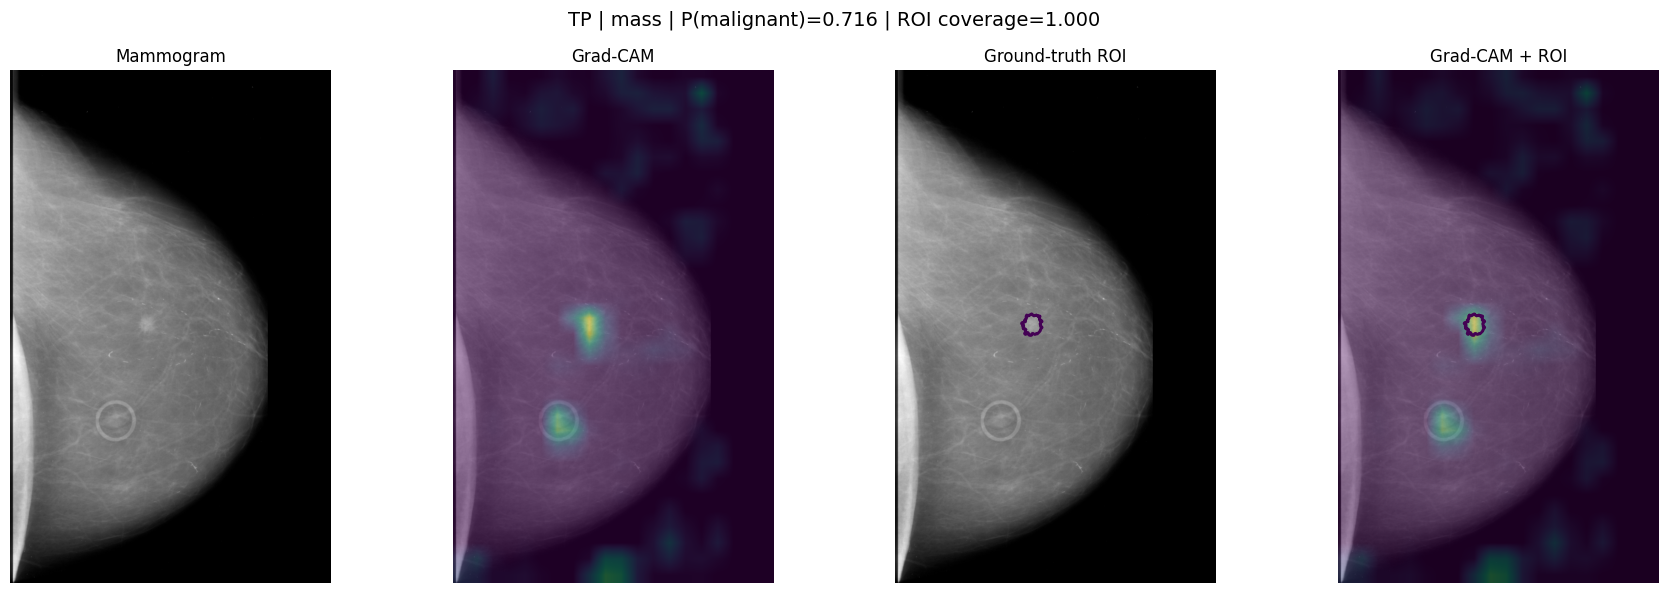

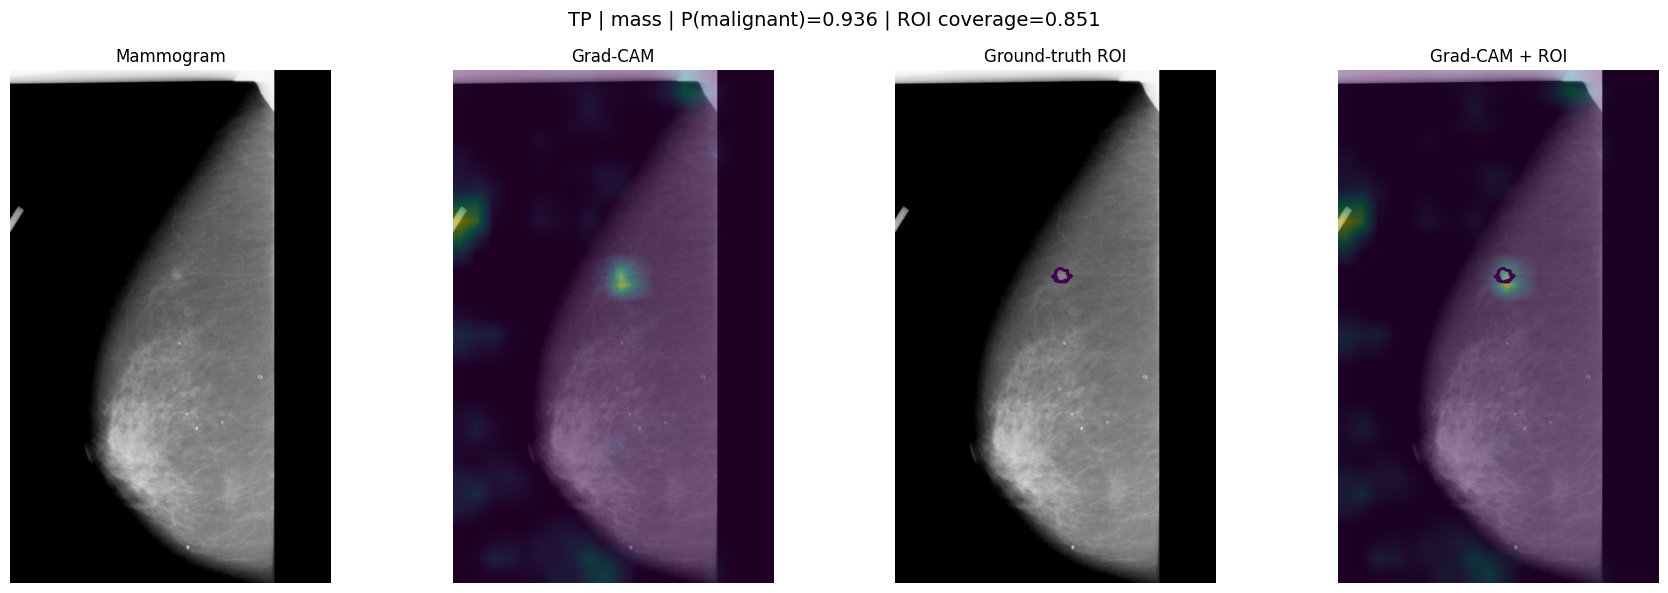

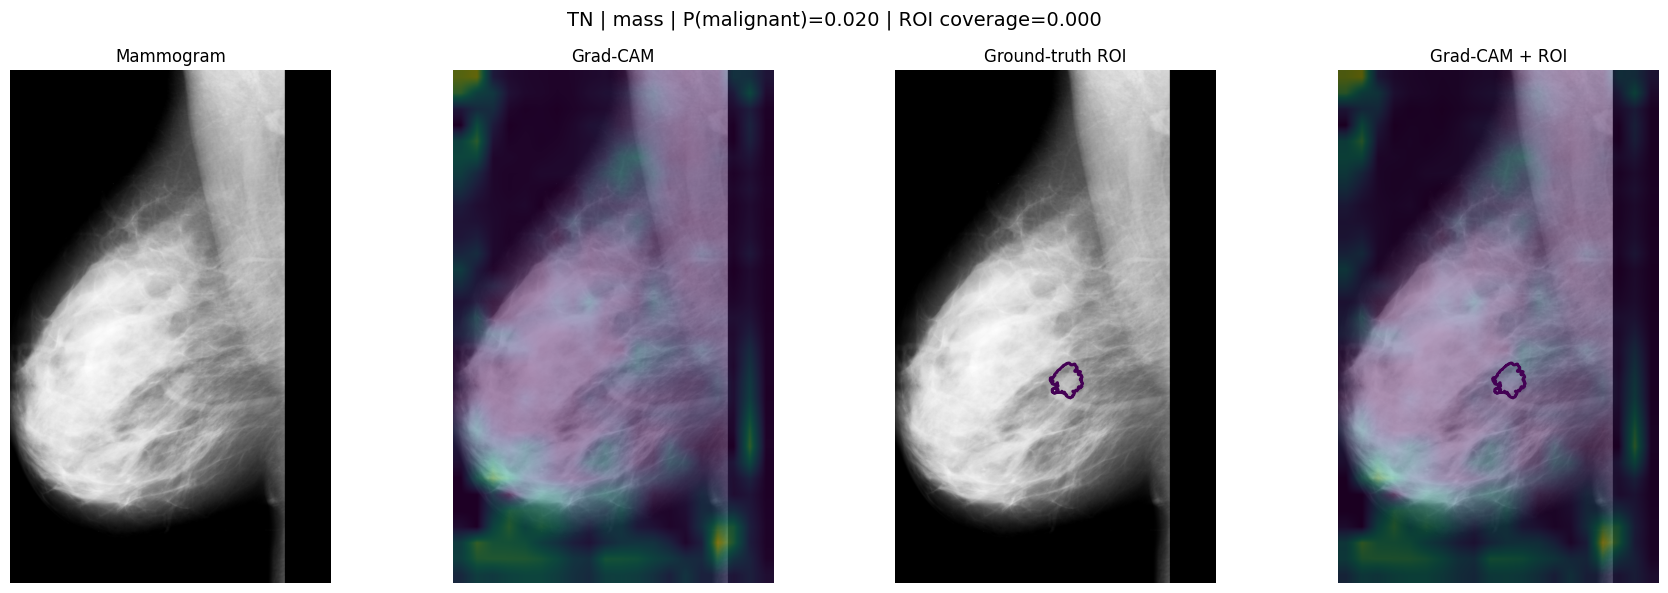

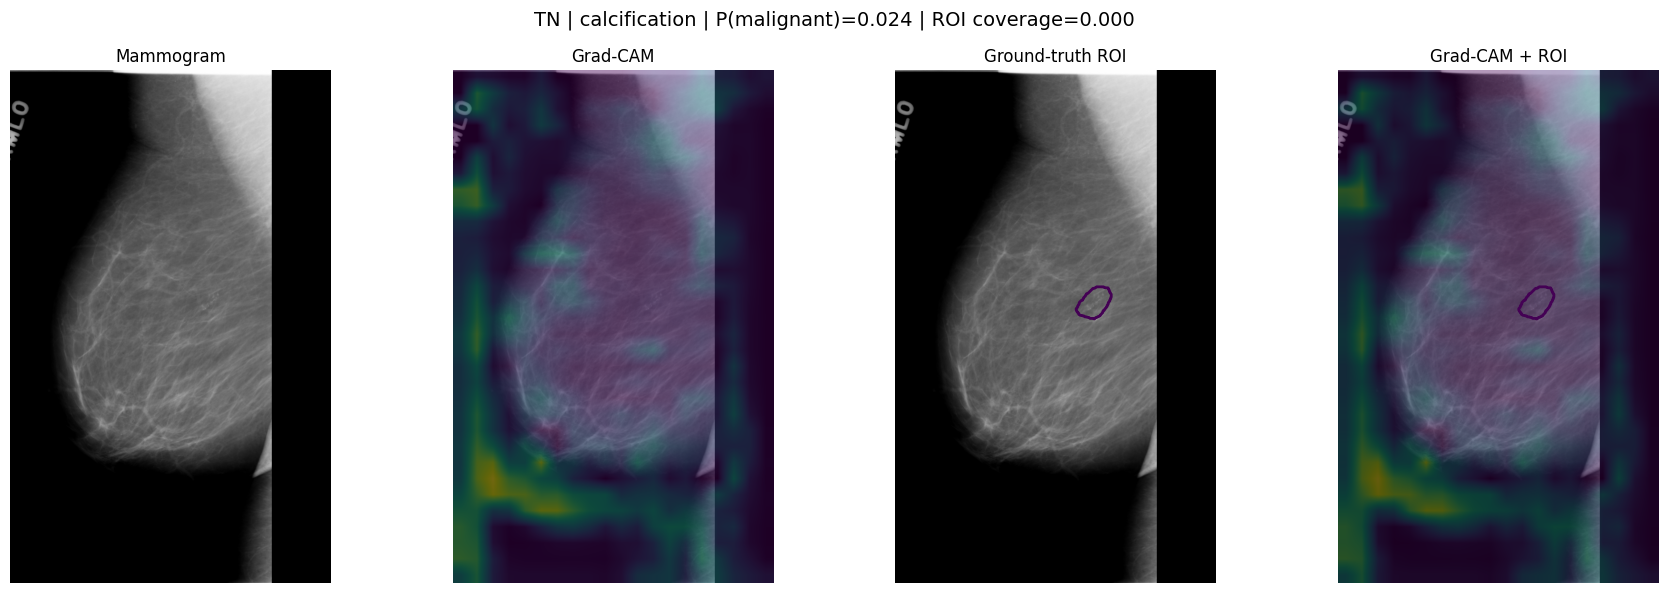

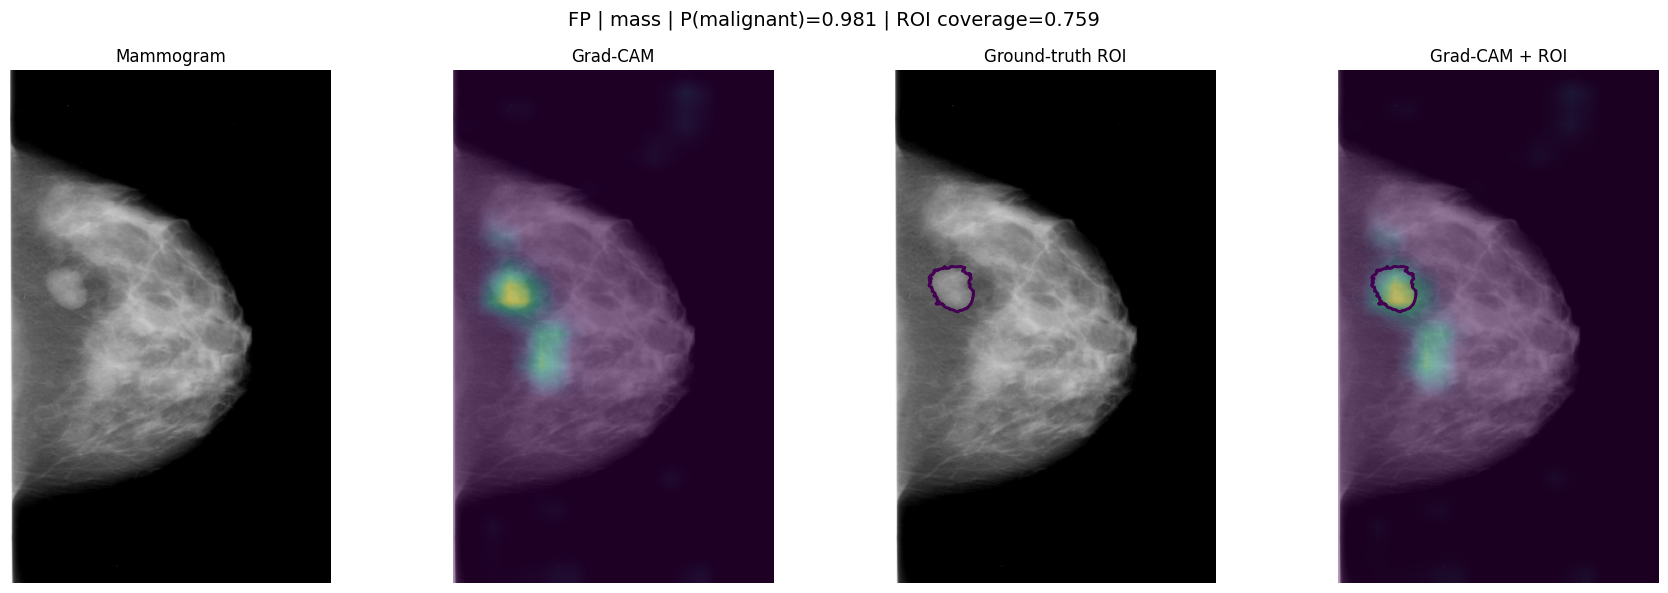

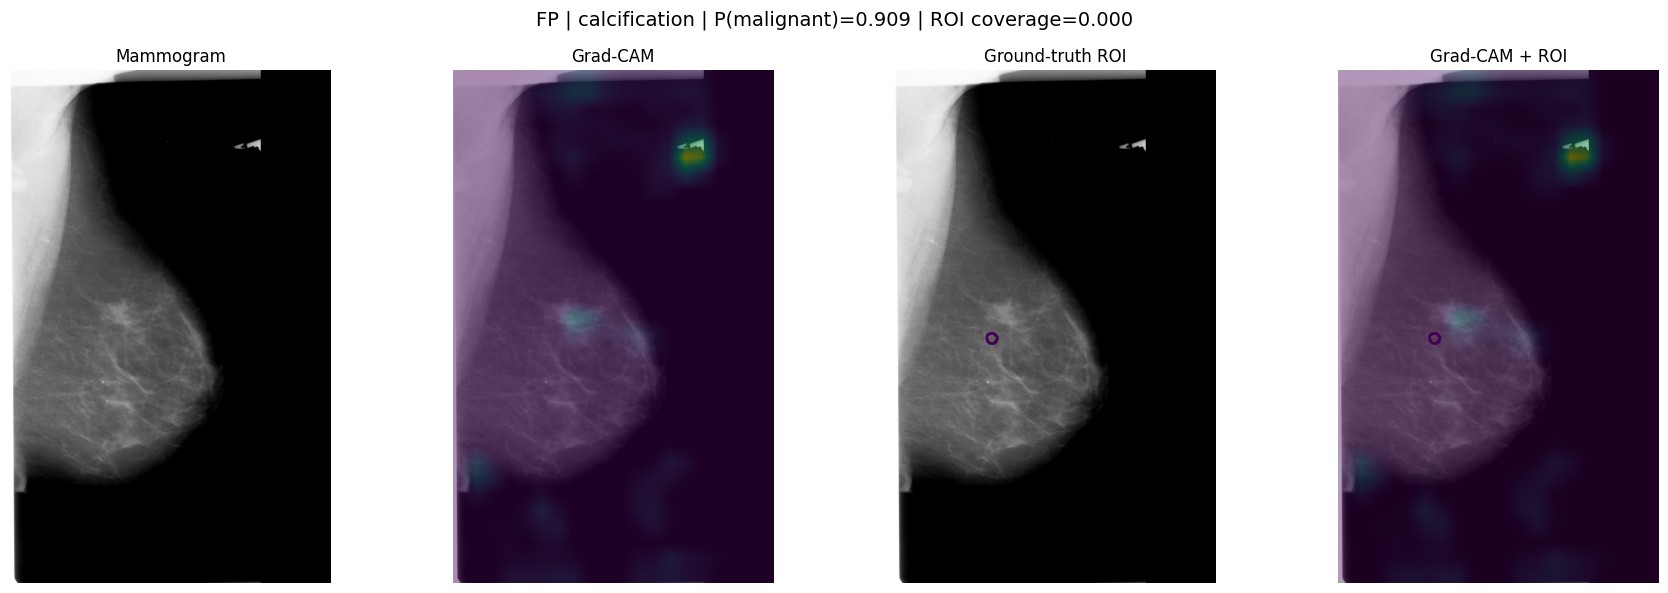

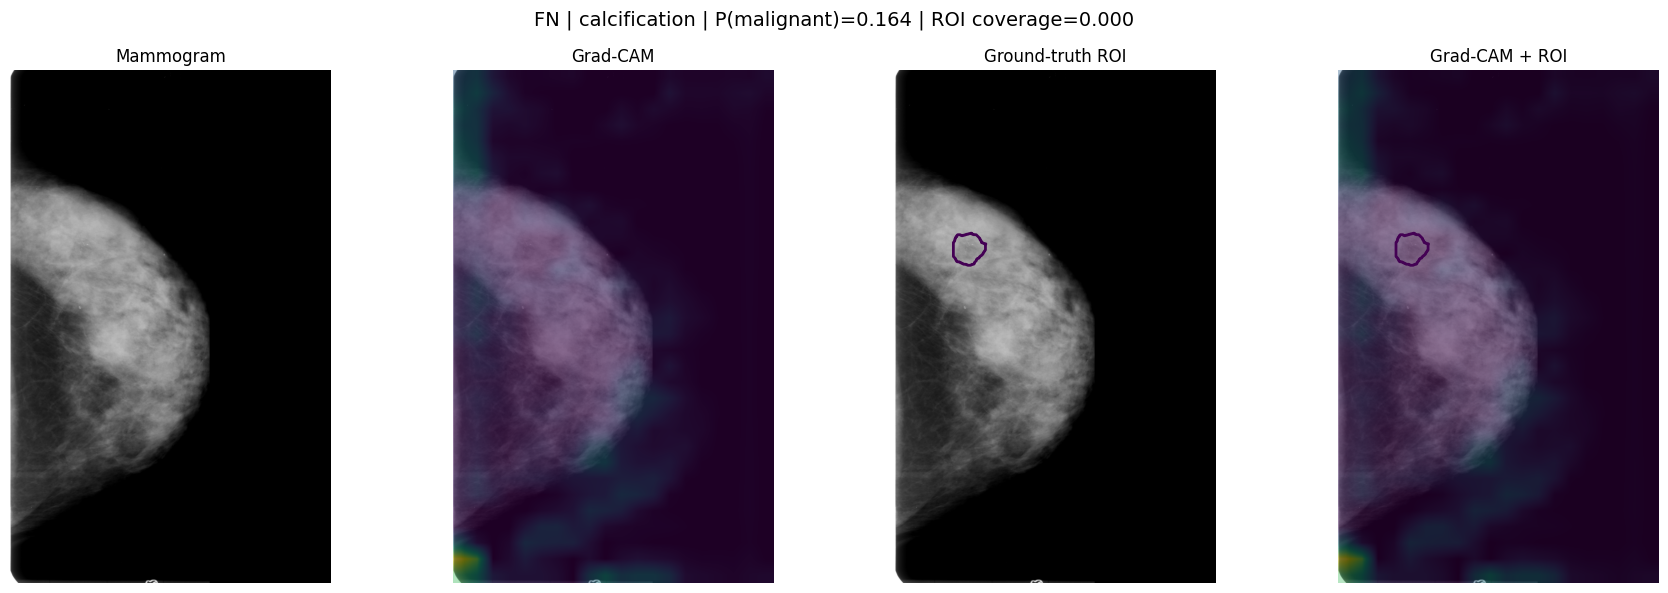

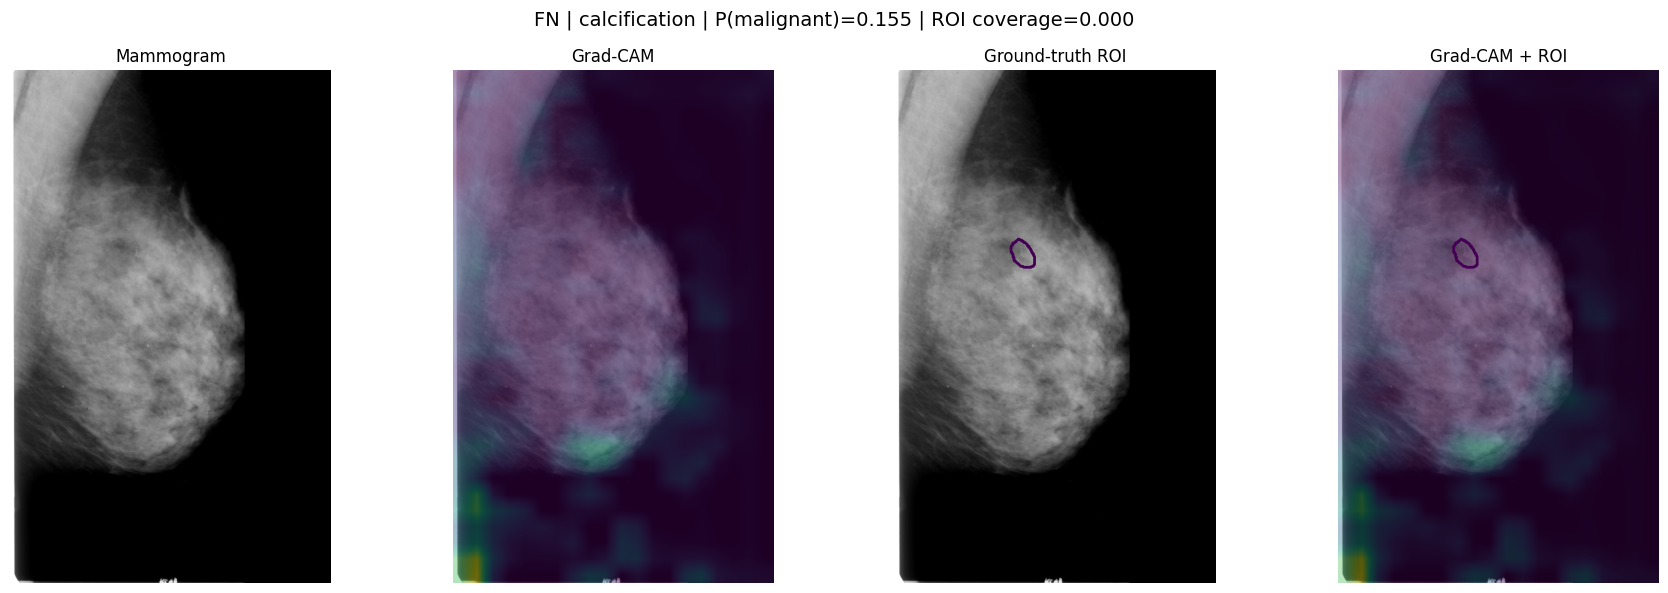

In [36]:
def save_gradcam_case(
    row,
    filename,
):

    image, image_tensor, metadata = (
        load_classifier_image(
            row[
                "image_key"
            ]
        )
    )


    cam = gradcam.generate(
        input_tensor=image_tensor,
        predicted_label=row[
            "predicted_label"
        ],
    )


    mask = cv2.imread(
        str(
            PROJECT_ROOT
            / metadata[
                "mask_path"
            ]
        ),
        cv2.IMREAD_GRAYSCALE,
    )


    mask = (
        mask > 0
    )


    fig, axes = plt.subplots(
        1,
        4,
        figsize=(
            18,
            6,
        ),
    )


    axes[0].imshow(
        image,
        cmap="gray",
    )

    axes[0].set_title(
        "Mammogram"
    )


    axes[1].imshow(
        image,
        cmap="gray",
    )

    axes[1].imshow(
        cam,
        alpha=0.45,
    )

    axes[1].set_title(
        "Grad-CAM"
    )


    axes[2].imshow(
        image,
        cmap="gray",
    )

    axes[2].contour(
        mask,
        levels=[0.5],
        linewidths=2,
    )

    axes[2].set_title(
        "Ground-truth ROI"
    )


    axes[3].imshow(
        image,
        cmap="gray",
    )

    axes[3].imshow(
        cam,
        alpha=0.40,
    )

    axes[3].contour(
        mask,
        levels=[0.5],
        linewidths=2,
    )

    axes[3].set_title(
        "Grad-CAM + ROI"
    )


    for ax in axes:
        ax.axis("off")


    fig.suptitle(
        (
            f"{row['outcome']} | "
            f"{row['abnormality_type']} | "
            f"P(malignant)="
            f"{row['probability']:.3f} | "
            f"ROI coverage="
            f"{row['roi_coverage']:.3f}"
        ),
        fontsize=14,
    )


    plt.tight_layout()


    save_path = (
        FIGURE_DIR
        / filename
    )


    plt.savefig(
        save_path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()


    return save_path

for _, row in (
    selected_cases_df.iterrows()
):

    filename = (
        f"{row['outcome']}_"
        f"{row['image_key']}.png"
    )

    filename = (
        filename
        .replace("/", "_")
        .replace("\\", "_")
    )

    save_gradcam_case(
        row=row,
        filename=filename,
    )

In [37]:
from pathlib import Path
import json
import shutil


# ============================================================
# FINAL GRAD-CAM ARTIFACT
# ============================================================

ARTIFACT_DIR = Path(
    "/kaggle/working/"
    "classifier_gradcam_artifact"
)

if ARTIFACT_DIR.exists():
    shutil.rmtree(
        ARTIFACT_DIR
    )

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


FIGURE_ARTIFACT_DIR = (
    ARTIFACT_DIR / "figures"
)

FIGURE_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# COPY CSV RESULTS
# ============================================================

files_to_copy = [
    "gradcam_roi_metrics.csv",
    "gradcam_metrics_by_outcome.csv",
    "gradcam_metrics_by_abnormality.csv",
]


for filename in files_to_copy:

    source = (
        OUTPUT_DIR / filename
    )

    if source.exists():

        shutil.copy2(
            source,
            ARTIFACT_DIR / filename,
        )


# ============================================================
# COPY FIGURES
# ============================================================

for figure_path in FIGURE_DIR.glob(
    "*.png"
):

    shutil.copy2(
        figure_path,
        FIGURE_ARTIFACT_DIR
        / figure_path.name,
    )


# ============================================================
# SAVE SUMMARY
# ============================================================

gradcam_summary = {

    "model":
        "ResNet50 classifier",

    "checkpoint":
        CLASSIFIER_CHECKPOINT_PATH.name,

    "target_layer":
        "layer4[-1]",

    "cam_threshold":
        0.5,

    "test_images":
        int(
            len(gradcam_df)
        ),

    "interpretation":
        (
            "Correct malignant predictions "
            "showed greater Grad-CAM overlap "
            "with annotated lesion ROIs than "
            "false negatives or benign predictions. "
            "Mass lesions showed stronger ROI "
            "alignment than calcifications. "
            "Overall attention remained diffuse, "
            "so Grad-CAM should be interpreted "
            "as qualitative classifier attention "
            "rather than precise lesion localization."
        ),

    "notes":
        (
            "Grad-CAM analysis used the final "
            "locked classifier checkpoint. "
            "No model retraining or threshold "
            "tuning was performed."
        ),
}


with open(
    ARTIFACT_DIR
    / "gradcam_summary.json",
    "w",
) as f:

    json.dump(
        gradcam_summary,
        f,
        indent=2,
    )


# ============================================================
# VERIFY
# ============================================================

print(
    "Grad-CAM artifact contents:"
)

print("=" * 60)


for path in sorted(
    ARTIFACT_DIR.rglob("*")
):

    if path.is_file():

        print(
            path.relative_to(
                ARTIFACT_DIR
            )
        )


# ============================================================
# ZIP
# ============================================================

zip_path = shutil.make_archive(
    "/kaggle/working/"
    "classifier_gradcam_artifact",
    "zip",
    ARTIFACT_DIR,
)


print(
    "\nZIP created:"
)

print(
    zip_path
)

Grad-CAM artifact contents:
figures/FN_P_00014_LEFT_CC.png
figures/FN_P_00014_LEFT_MLO.png
figures/FP_P_00531_RIGHT_MLO.png
figures/FP_P_01447_RIGHT_CC.png
figures/TN_P_01755_RIGHT_MLO.png
figures/TN_P_01773_RIGHT_MLO.png
figures/TP_P_00023_RIGHT_CC.png
figures/TP_P_00218_LEFT_CC.png
gradcam_metrics_by_abnormality.csv
gradcam_metrics_by_outcome.csv
gradcam_roi_metrics.csv
gradcam_summary.json

ZIP created:
/kaggle/working/classifier_gradcam_artifact.zip
